<a href="https://colab.research.google.com/github/yoggalih/Klasifikasi-Engagement-Level-Fisiologis-dan-Lingkungan-menggunakan-XGBoost-dan-CatBoost/blob/main/BISMILLAHFIKS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ANALISIS STATISTIK DAN KUALITAS DATA**

In [ ]:
# =======================================================
# INSTALL LIBRARY
# =======================================================

!pip install xgboost catboost

# =======================================================
# IMPORT LIBRARY
# =======================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.3 MB/s eta 0:00:00


In [ ]:

# =======================================================
# LOAD DATASET
# =======================================================

df = pd.read_csv('emotional_monitoring_dataset_with_target.csv')

print("Jumlah Baris dan Kolom Dataset:")
print(df.shape)

# =======================================================
# MENAMPILKAN SELURUH DATASET
# =======================================================

print("5 Data Pertama Dataset:\n")

# Menggunakan to_markdown() untuk tampilan tabel yang lebih rapi dan ringkas
print(
    df.head().to_markdown(index=False)
)


Jumlah Baris dan Kolom Dataset:
(1000, 14)
5 Data Pertama Dataset:

|   HeartRate |   SkinConductance |       EEG |   Temperature |   PupilDiameter |   SmileIntensity |   FrownIntensity |   CortisolLevel |   ActivityLevel |   AmbientNoiseLevel |   LightingLevel | EmotionalState    | CognitiveState   |   EngagementLevel |
|------------:|------------------:|----------:|--------------:|----------------:|-----------------:|-----------------:|----------------:|----------------:|--------------------:|----------------:|:------------------|:-----------------|------------------:|
|          61 |          8.9372   | 11.7949   |       36.5017 |         3.33018 |         0.689238 |        0.189024  |        0.603035 |             136 |                  59 |             394 | engaged           | distracted       |                 3 |
|          60 |         12.6354   | 19.1514   |       36.6189 |         3.429   |         0.561056 |        0.0913671 |        0.566671 |             155 |            

In [ ]:

# =======================================================
# PEMERIKSAAN MISSING VALUE
# =======================================================

print("\n" + "="*50 + "\nPEMERIKSAAN MISSING VALUE\n" + "="*50)
print(df.isnull().sum())


# =======================================================
# VALIDASI TIPE DATA
# =======================================================

print("\n" + "="*50 + "\nVALIDASI TIPE DATA\n" + "="*50)
print(df.dtypes)

# =======================================================
# ANALISIS STATISTIK DESKRIPTIF
# =======================================================

print("\n" + "="*50 + "\nANALISIS STATISTIK DESKRIPTIF\n" + "="*50)
print(df.describe())


# =======================================================
# DETEKSI OUTLIER MENGGUNAKAN IQR
# =======================================================

print("\n" + "="*50 + "\nDETEKSI OUTLIER MENGGUNAKAN IQR\n" + "="*50)
numerical_cols = df.select_dtypes(include=np.number).columns.drop('EngagementLevel')

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"{col}: {len(outliers)} outlier")

# =======================================================
# DETEKSI DUPLIKAT
# =======================================================

print("\n" + "="*50 + "\nDETEKSI DUPLIKAT\n" + "="*50)
print(df.duplicated().sum())



# =======================================================
# ANALISIS DISTRIBUSI DATA
# =======================================================
print("\n" + "="*50 + "\nANALISIS DISTRIBUSI DATA\n" + "="*50)
print("Distribusi kelas untuk variabel target y (EngagementLevel):")
print(df['EngagementLevel'].value_counts())

# =======================================================
# UJI VALIDITAS FITUR MENGGUNAKAN KRUSKAL-WALLIS
# =======================================================

print("\n" + "="*50 + "\nUJI VALIDITAS FITUR MENGGUNAKAN KRUSKAL-WALLIS\n" + "="*50)

for col in numerical_cols:
    groups = [
        group[col].values
        for name, group in df.groupby('EngagementLevel')
    ]

    stat, p = kruskal(*groups)

    if p < 0.05:
        hasil = "Signifikan"
    else:
        hasil = "Tidak"

    print(f"{col}: p={p:.5f} -> {hasil}")


PEMERIKSAAN MISSING VALUE
HeartRate            0
SkinConductance      0
EEG                  0
Temperature          0
PupilDiameter        0
SmileIntensity       0
FrownIntensity       0
CortisolLevel        0
ActivityLevel        0
AmbientNoiseLevel    0
LightingLevel        0
EmotionalState       0
CognitiveState       0
EngagementLevel      0
dtype: int64

VALIDASI TIPE DATA
HeartRate              int64
SkinConductance      float64
EEG                  float64
Temperature          float64
PupilDiameter        float64
SmileIntensity       float64
FrownIntensity       float64
CortisolLevel        float64
ActivityLevel          int64
AmbientNoiseLevel      int64
LightingLevel          int64
EmotionalState        object
CognitiveState        object
EngagementLevel        int64
dtype: object

ANALISIS STATISTIK DESKRIPTIF
         HeartRate  SkinConductance          EEG  Temperature  PupilDiameter  \
count  1000.000000      1000.000000  1000.000000  1000.000000    1000.000000   
mean   

In [ ]:
# =======================================================
# MENGHAPUS FITUR YANG TIDAK DIGUNAKAN
# =======================================================

df = df.drop(
    columns=['EmotionalState', 'CognitiveState']
)


In [ ]:
# =======================================================
# PEMISAHAN FITUR DAN TARGET
# =======================================================

X = df.drop('EngagementLevel', axis=1)
y = df['EngagementLevel']


# =======================================================
# PENYESUAIAN LABEL TARGET
# =======================================================

y = y - 1


# =======================================================
# SKENARIO PENGUJIAN DATA
# =======================================================

fitur_fisiologis = [
    'HeartRate',
    'SkinConductance',
    'EEG',
    'Temperature',
    'PupilDiameter',
    'SmileIntensity',
    'FrownIntensity',
    'CortisolLevel',
    'ActivityLevel'
]

fitur_lingkungan = [
    'AmbientNoiseLevel',
    'LightingLevel'
]

fitur_multimodal = (
    fitur_fisiologis +
    fitur_lingkungan
)

X_fisiologis = X[fitur_fisiologis]

X_lingkungan = X[fitur_lingkungan]

X_multimodal = X[fitur_multimodal]

In [ ]:
# =======================================================
# PEMBAGIAN DATA LATIH DAN DATA UJI
# =======================================================

# Fisiologis
X_train_fisio, X_test_fisio, y_train_fisio, y_test_fisio = train_test_split(
    X_fisiologis,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Lingkungan
X_train_ling, X_test_ling, y_train_ling, y_test_ling = train_test_split(
    X_lingkungan,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Multimodal
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multimodal,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
print("Daftar Fitur Kategori Fisiologis:")
for feature in fitur_fisiologis:
    print(f"- {feature}")

print("\nDaftar Fitur Kategori Lingkungan:")
for feature in fitur_lingkungan:
    print(f"- {feature}")

print("\nDaftar Fitur Kategori Multimodal:")
for feature in fitur_multimodal:
    print(f"- {feature}")

Daftar Fitur Kategori Fisiologis:
- HeartRate
- SkinConductance
- EEG
- Temperature
- PupilDiameter
- SmileIntensity
- FrownIntensity
- CortisolLevel
- ActivityLevel

Daftar Fitur Kategori Lingkungan:
- AmbientNoiseLevel
- LightingLevel

Daftar Fitur Kategori Multimodal:
- HeartRate
- SkinConductance
- EEG
- Temperature
- PupilDiameter
- SmileIntensity
- FrownIntensity
- CortisolLevel
- ActivityLevel
- AmbientNoiseLevel
- LightingLevel


In [ ]:
print("Distribusi kelas di data latih (Fisiologis):\n", y_train_fisio.value_counts())
print("Distribusi kelas di data uji (Fisiologis):\n", y_test_fisio.value_counts())

print("\nDistribusi kelas di data latih (Lingkungan):\n", y_train_ling.value_counts())
print("Distribusi kelas di data uji (Lingkungan):\n", y_test_ling.value_counts())

print("\nDistribusi kelas di data latih (Multimodal):\n", y_train_multi.value_counts())
print("Distribusi kelas di data uji (Multimodal):\n", y_test_multi.value_counts())

Distribusi kelas di data latih (Fisiologis):
 EngagementLevel
2    463
1    259
0     78
Name: count, dtype: int64
Distribusi kelas di data uji (Fisiologis):
 EngagementLevel
2    116
1     65
0     19
Name: count, dtype: int64

Distribusi kelas di data latih (Lingkungan):
 EngagementLevel
2    463
1    259
0     78
Name: count, dtype: int64
Distribusi kelas di data uji (Lingkungan):
 EngagementLevel
2    116
1     65
0     19
Name: count, dtype: int64

Distribusi kelas di data latih (Multimodal):
 EngagementLevel
2    463
1    259
0     78
Name: count, dtype: int64
Distribusi kelas di data uji (Multimodal):
 EngagementLevel
2    116
1     65
0     19
Name: count, dtype: int64


In [ ]:
# ============================================================
# PELATIHAN MODEL XGBOOST
# ============================================================

# Skenario Fisiologis
xgb_fisio = XGBClassifier(
    eval_metric='mlogloss',
    random_state=42,
    n_estimators=100
)
xgb_fisio.fit(X_train_fisio, y_train_fisio)

# Skenario Lingkungan
xgb_ling = XGBClassifier(
    eval_metric='mlogloss',
    random_state=42,
    n_estimators=100
)
xgb_ling.fit(X_train_ling, y_train_ling)

# Skenario Multimodal
xgb_multi = XGBClassifier(
    eval_metric='mlogloss',
    random_state=42,
    n_estimators=100
)
xgb_multi.fit(X_train_multi, y_train_multi)


# ============================================================
# PREDIKSI DATA UJI XGBOOST
# TAMBAHAN / PERBAIKAN
# ============================================================

y_pred_xgb_fisio = xgb_fisio.predict(X_test_fisio)

y_pred_xgb_ling = xgb_ling.predict(X_test_ling)

y_pred_xgb_multi = xgb_multi.predict(X_test_multi)

In [ ]:
# ============================================================
# PELATIHAN MODEL CATBOOST
# ============================================================

# Skenario Fisiologis
cat_fisio = CatBoostClassifier(
    random_state=42,
    verbose=0,
    iterations=1000
)
cat_fisio.fit(X_train_fisio, y_train_fisio)

# Skenario Lingkungan
cat_ling = CatBoostClassifier(
    random_state=42,
    verbose=0,
    iterations=1000
)
cat_ling.fit(X_train_ling, y_train_ling)

# Skenario Multimodal
cat_multi = CatBoostClassifier(
    random_state=42,
    verbose=0,
    iterations=1000
)
cat_multi.fit(X_train_multi, y_train_multi)


# ============================================================
# PREDIKSI DATA UJI CATBOOST
# ============================================================

y_pred_cat_fisio = cat_fisio.predict(X_test_fisio)

y_pred_cat_ling = cat_ling.predict(X_test_ling)

y_pred_cat_multi = cat_multi.predict(X_test_multi)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def print_metrics(model_name, scenario_name, y_true, y_pred):
    print(f"\n--- {model_name} - Skenario {scenario_name} ---")
    print("Accuracy:", accuracy_score(y_true, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# XGBoost
print_metrics("XGBoost", "Fisiologis", y_test_fisio, y_pred_xgb_fisio);
print_metrics("XGBoost", "Lingkungan", y_test_ling, y_pred_xgb_ling);
print_metrics("XGBoost", "Multimodal", y_test_multi, y_pred_xgb_multi);

# CatBoost
print_metrics("CatBoost", "Fisiologis", y_test_fisio, y_pred_cat_fisio);
print_metrics("CatBoost", "Lingkungan", y_test_ling, y_pred_cat_ling);
print_metrics("CatBoost", "Multimodal", y_test_multi, y_pred_cat_multi);


--- XGBoost - Skenario Fisiologis ---
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        65
           2       1.00      1.00      1.00       116

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200


Confusion Matrix:
[[ 19   0   0]
 [  0  65   0]
 [  0   0 116]]

--- XGBoost - Skenario Lingkungan ---
Accuracy: 0.43

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        19
           1       0.22      0.18      0.20        65
           2       0.54      0.64      0.58       116

    accuracy                           0.43       200
   macro avg       0.25      0.27      0.26       200
weighted avg       0.38      0.43      0.40       200


Confusion Matrix:

In [ ]:
from sklearn.metrics import accuracy_score
import pandas as pd

# Calculate direct test set accuracies
accuracy_xgb_fisio = accuracy_score(y_test_fisio, y_pred_xgb_fisio) * 100
accuracy_cat_fisio = accuracy_score(y_test_fisio, y_pred_cat_fisio) * 100

accuracy_xgb_ling = accuracy_score(y_test_ling, y_pred_xgb_ling) * 100
accuracy_cat_ling = accuracy_score(y_test_ling, y_pred_cat_ling) * 100

accuracy_xgb_multi = accuracy_score(y_test_multi, y_pred_xgb_multi) * 100
accuracy_cat_multi = accuracy_score(y_test_multi, y_pred_cat_multi) * 100

# Create a dictionary for the new table format
data_perbandingan = {
    'XGBoost': [
        f'{accuracy_xgb_fisio:.1f}%',
        f'{accuracy_xgb_ling:.1f}%',
        f'{accuracy_xgb_multi:.1f}%'
    ],
    'CatBoost': [
        f'{accuracy_cat_fisio:.1f}%',
        f'{accuracy_cat_ling:.1f}%',
        f'{accuracy_cat_multi:.1f}%'
    ]
}

# Create a DataFrame
df_perbandingan_test = pd.DataFrame(
    data_perbandingan,
    index=['Fisiologis', 'Lingkungan', 'Multimodal']
)

print("\n=== Perbandingan Akurasi Data Uji Langsung ===")
print(df_perbandingan_test.to_markdown())


=== Perbandingan Akurasi Data Uji Langsung ===
|            | XGBoost   | CatBoost   |
|:-----------|:----------|:-----------|
| Fisiologis | 100.0%    | 99.5%      |
| Lingkungan | 43.0%     | 48.5%      |
| Multimodal | 100.0%    | 99.5%      |


In [ ]:
# =======================================================
# VALIDASI TAMBAHAN: 5-FOLD STRATIFIED CROSS-VALIDATION
# =======================================================

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

xgb_model = XGBClassifier(eval_metric='mlogloss', random_state=42)
cat_model = CatBoostClassifier(random_state=42, verbose=0)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

skenario_list = {
    'Fisiologis': X_fisiologis,
    'Lingkungan': X_lingkungan,
    'Multimodal': X_multimodal
}

hasil_cv = []

for nama_skenario, X_data in skenario_list.items():
    cv_xgb = cross_validate(xgb_model, X_data, y, cv=skf, scoring=scoring)
    print(f"\n[XGBoost - {nama_skenario}] Accuracy tiap fold:", cv_xgb['test_accuracy'])

    hasil_cv.append({
        'Algoritma': 'XGBoost', 'Skenario': nama_skenario,
        'Accuracy (mean)': cv_xgb['test_accuracy'].mean(),
        'Accuracy (std)': cv_xgb['test_accuracy'].std(),
        'Precision (mean)': cv_xgb['test_precision_macro'].mean(),
        'Recall (mean)': cv_xgb['test_recall_macro'].mean(),
        'F1-score (mean)': cv_xgb['test_f1_macro'].mean(),
    })

    cv_cat = cross_validate(cat_model, X_data, y, cv=skf, scoring=scoring)
    print(f"[CatBoost - {nama_skenario}] Accuracy tiap fold:", cv_cat['test_accuracy'])

    hasil_cv.append({
        'Algoritma': 'CatBoost', 'Skenario': nama_skenario,
        'Accuracy (mean)': cv_cat['test_accuracy'].mean(),
        'Accuracy (std)': cv_cat['test_accuracy'].std(),
        'Precision (mean)': cv_cat['test_precision_macro'].mean(),
        'Recall (mean)': cv_cat['test_recall_macro'].mean(),
        'F1-score (mean)': cv_cat['test_f1_macro'].mean(),
    })

df_hasil_cv = pd.DataFrame(hasil_cv)
kolom_persen = ['Accuracy (mean)', 'Accuracy (std)', 'Precision (mean)', 'Recall (mean)', 'F1-score (mean)']
df_hasil_cv[kolom_persen] = df_hasil_cv[kolom_persen] * 100

print("\n=== RINGKASAN HASIL CROSS-VALIDATION ===")
print(df_hasil_cv.round(2).to_string(index=False))


[XGBoost - Fisiologis] Accuracy tiap fold: [0.995 1.    1.    1.    0.995]
[CatBoost - Fisiologis] Accuracy tiap fold: [0.99  0.99  1.    1.    0.995]

[XGBoost - Lingkungan] Accuracy tiap fold: [0.435 0.455 0.455 0.445 0.425]
[CatBoost - Lingkungan] Accuracy tiap fold: [0.48  0.45  0.505 0.495 0.485]

[XGBoost - Multimodal] Accuracy tiap fold: [0.995 1.    1.    1.    0.995]
[CatBoost - Multimodal] Accuracy tiap fold: [0.99  0.99  1.    1.    0.995]

=== RINGKASAN HASIL CROSS-VALIDATION ===
Algoritma   Skenario  Accuracy (mean)  Accuracy (std)  Precision (mean)  Recall (mean)  F1-score (mean)
  XGBoost Fisiologis             99.8            0.24             99.37          99.88            99.62
 CatBoost Fisiologis             99.5            0.45             99.18          98.85            98.99
  XGBoost Lingkungan             44.3            1.17             27.99          29.38            28.48
 CatBoost Lingkungan             48.3            1.86             28.75          30.86

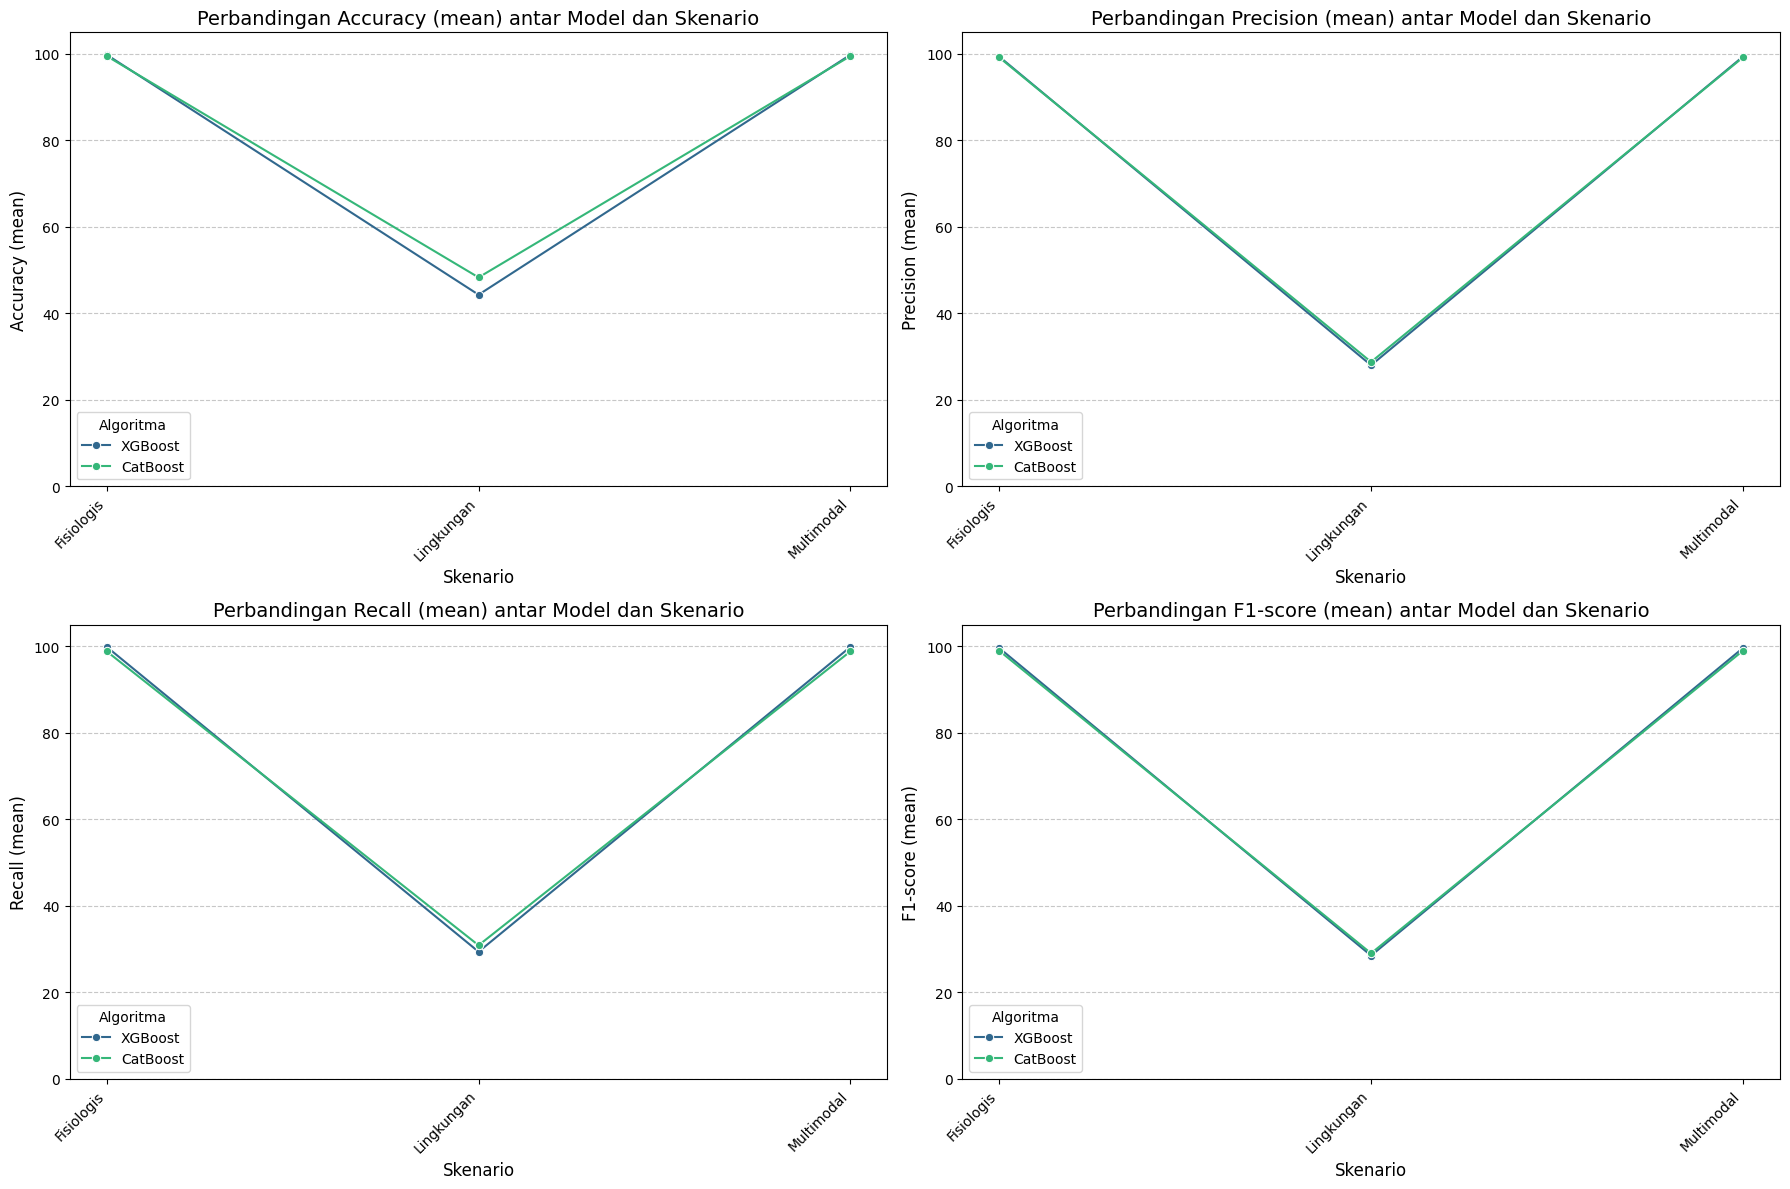

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df_hasil_cv is available
# If df_hasil_cv is not defined, you might need to re-run the previous cells
# where it was created and populated.
# For the purpose of this request, I'll assume df_hasil_cv is already in the kernel state.

# The 'Model_Scenario' column is not directly used for line plots in this configuration
# if 'Model_Scenario' not in df_hasil_cv.columns:
#     df_hasil_cv['Model_Scenario'] = df_hasil_cv['Algoritma'] + ' (' + df_hasil_cv['Skenario'] + ')'

metrics = ['Accuracy (mean)', 'Precision (mean)', 'Recall (mean)', 'F1-score (mean)']

plt.figure(figsize=(18, 12))

for i, metric in enumerate(metrics):
    plt.subplot(2, 2, i + 1)
    # Changed from barplot to lineplot
    sns.lineplot(x='Skenario', y=metric, hue='Algoritma', data=df_hasil_cv, marker='o', palette='viridis')
    plt.title(f'Perbandingan {metric} antar Model dan Skenario', fontsize=14)
    plt.xlabel('Skenario', fontsize=12)
    plt.ylabel(metric, fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)
    plt.ylim(0, 105) # Metrics are multiplied by 100 in df_hasil_cv, so max is 100
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend(title='Algoritma') # Added legend explicitly

plt.tight_layout()
plt.show()